# Notebook 8 — Failure Analysis: What Is the Model Picking Up?

Notebook 6 found that a classifier on a **single static frame** matches the CNN + LSTM, so the advantage over optical
flow comes from the pretrained visual features rather than from temporal modelling. That raises a question the
accuracy numbers cannot answer:

> Is the model detecting an *imminent-collision cue*, or is it recognising *scene/video-level appearance* that happens to
> differ between collision and normal videos?

This notebook probes that question using only the cached ResNet features and the clip/event metadata (the raw videos are
not needed). The analyses are descriptive and say what the data are consistent with, not why a model decides.

| Section | Question |
|---|---|
| 1–2 | Re-create the Notebook 6 predictions (so errors can be inspected) and verify they match. |
| 3 | **Frame position:** does a frame from 3 s before the event predict as well as one from 0.5 s before? |
| 4 | **Alert timing:** are positive clips still detected when they end *before* the annotators' alert time (hazard not yet apparent)? |
| 5 | **Shortcut checks:** can metadata alone (prediction time, video id) separate the classes? |
| 6 | **Where do errors occur** (position in the video)? |
| 7 | **Which videos fail** at every horizon (list for visual inspection)? |

The 300 official validation videos are used as the held-out test set, as in Notebook 7.

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROCESSED_DIR = Path("./data/processed")
FEATURE_DIR = PROCESSED_DIR / "cnn_features"
RESULTS_DIR = Path("./results")
FIGURE_DIR = RESULTS_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

TTE_VALUES = [0.5, 1.0, 1.5]
SEEDS = [42, 43, 44, 45, 46]
NUM_EPOCHS, BATCH_SIZE, LEARNING_RATE, HIDDEN_SIZE, FEATURE_DIM = 10, 32, 1e-3, 128, 512   # Notebook 6 settings
INNER_VAL_FRACTION, INNER_SPLIT_SEED = 0.2, 42
CLIP_DURATION, NUM_FRAMES = 2.0, 16
N_BOOTSTRAP = 2000
torch.set_num_threads(4)

# Plot style (same tokens as Notebook 7): blue = CNN + LSTM, orange = optical flow, grey = controls/references.
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, NEUTRAL = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})

## 1. Load features, labels and clip metadata

In [2]:
train_clips = pd.read_csv(PROCESSED_DIR / "train_clips.csv")
val_clips = pd.read_csv(PROCESSED_DIR / "val_clips.csv")
val_split = pd.read_csv(PROCESSED_DIR / "val_split.csv")

X_train, y_train, X_val, y_val, val_meta = {}, {}, {}, {}, {}
for tte in TTE_VALUES:
    tr = train_clips[train_clips["tte"] == tte].reset_index(drop=True)
    va = val_clips[val_clips["tte"] == tte].reset_index(drop=True)
    X_train[tte] = np.load(FEATURE_DIR / f"train_tte_{tte}.npy")
    X_val[tte] = np.load(FEATURE_DIR / f"val_tte_{tte}.npy")
    y_train[tte] = tr["target"].to_numpy().astype(int)
    y_val[tte] = va["target"].to_numpy().astype(int)
    va["id"] = va["id"].astype(float).astype(int)
    val_meta[tte] = va.merge(val_split.assign(id=val_split["id"].astype(int))[["id", "time_of_event", "time_of_alert"]],
                             on="id", how="left")
    assert len(val_meta[tte]) == len(X_val[tte]) == len(y_val[tte])
    assert np.array_equal(val_meta[tte]["target"].to_numpy(), y_val[tte])

# Positives must have event/alert times; negatives must not.
m = val_meta[1.0]
assert m.loc[m["target"] == 1, ["time_of_event", "time_of_alert"]].notna().all().all()
assert m.loc[m["target"] == 0, ["time_of_event", "time_of_alert"]].isna().all().all()
# For positives, the clip must end exactly TTE seconds before the event.
for tte in TTE_VALUES:
    pos = val_meta[tte][val_meta[tte]["target"] == 1]
    assert np.allclose(pos["time_of_event"] - pos["prediction_time"], tte, atol=1e-6)
print("Loaded features and metadata; event-time arithmetic verified.")

inner = {}
for tte in TTE_VALUES:
    idx = np.arange(len(y_train[tte]))
    inner[tte] = train_test_split(idx, test_size=INNER_VAL_FRACTION, stratify=y_train[tte], random_state=INNER_SPLIT_SEED)

Loaded features and metadata; event-time arithmetic verified.


## 2. Re-create the Notebook 6 predictions

Notebook 6 did not save per-clip predictions, so we retrain with the **identical protocol** (same seeds, 10 epochs, epoch chosen on the
inner training split) and keep the test-set probabilities. A check against Notebook 6's saved bootstrap table confirms the
reproduction. Probabilities are averaged over the 5 seeds (a seed ensemble).

In [3]:
class CNNLSTM(nn.Module):
    def __init__(self, input_size=FEATURE_DIM, hidden_size=HIDDEN_SIZE):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, num_layers=1, batch_first=True)
        self.classifier = nn.Linear(hidden_size, 1)

    def forward(self, x):
        _, (hidden_state, _) = self.lstm(x)
        return self.classifier(hidden_state[-1]).squeeze(1)


class FrameMLP(nn.Module):
    """Classifier on one chosen frame position (index 15 = the frame at the prediction time)."""
    def __init__(self, index=-1, input_size=FEATURE_DIM, hidden_size=HIDDEN_SIZE):
        super().__init__()
        self.index = index
        self.net = nn.Sequential(nn.Linear(input_size, hidden_size), nn.ReLU(), nn.Linear(hidden_size, 1))

    def forward(self, x):
        return self.net(x[:, self.index]).squeeze(1)


class MeanPoolMLP(nn.Module):
    def __init__(self, input_size=FEATURE_DIM, hidden_size=HIDDEN_SIZE):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(input_size, hidden_size), nn.ReLU(), nn.Linear(hidden_size, 1))

    def forward(self, x):
        return self.net(x.mean(dim=1)).squeeze(1)


def predict_prob(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.as_tensor(X, dtype=torch.float32))).numpy()


def train_and_predict(model_ctor, tte, seed):
    """Train as in Notebook 6; return test-set probabilities at the epoch with the best inner-validation AP."""
    fit_idx, sel_idx = inner[tte]
    Xfit, yfit = X_train[tte][fit_idx], y_train[tte][fit_idx]
    Xsel, ysel = X_train[tte][sel_idx], y_train[tte][sel_idx]

    torch.manual_seed(seed)
    np.random.seed(seed)
    model = model_ctor()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.BCEWithLogitsLoss()
    Xfit_t = torch.as_tensor(Xfit, dtype=torch.float32)
    yfit_t = torch.as_tensor(yfit, dtype=torch.float32)

    best_ap, best_prob = -np.inf, None
    for _ in range(NUM_EPOCHS):
        model.train()
        perm = torch.randperm(len(Xfit_t))
        for start in range(0, len(perm), BATCH_SIZE):
            batch = perm[start:start + BATCH_SIZE]
            optimizer.zero_grad()
            criterion(model(Xfit_t[batch]), yfit_t[batch]).backward()
            optimizer.step()
        inner_ap = average_precision_score(ysel, predict_prob(model, Xsel))
        if inner_ap > best_ap:                       # first maximum, as np.argmax in Notebook 6
            best_ap, best_prob = inner_ap, predict_prob(model, X_val[tte])
    return best_prob


MODELS = {"lstm": CNNLSTM, "last_frame": FrameMLP, "mean_pool": MeanPoolMLP}
t0 = time.time()
ens = {}
for name, ctor in MODELS.items():
    for tte in TTE_VALUES:
        ens[(name, tte)] = np.mean([train_and_predict(ctor, tte, s) for s in SEEDS], axis=0)
print(f"Retrained {len(MODELS) * len(TTE_VALUES) * len(SEEDS)} models in {(time.time() - t0) / 60:.1f} min")

# Optical flow (deterministic refit, as in Notebook 6).
for tte in TTE_VALUES:
    flow = Pipeline([("s", StandardScaler()), ("c", LogisticRegression(max_iter=1000, random_state=42))])
    flow.fit(np.load(PROCESSED_DIR / f"X_train_flow_tte_{tte}.npy"), np.load(PROCESSED_DIR / f"y_train_flow_tte_{tte}.npy").astype(int))
    ens[("optical_flow", tte)] = flow.predict_proba(np.load(PROCESSED_DIR / f"X_val_flow_tte_{tte}.npy"))[:, 1]

# Verify against Notebook 6's saved seed-ensemble APs.
saved = pd.read_csv(RESULTS_DIR / "temporal_ablation_bootstrap.csv")
for name, label in [("lstm", "AP: CNN + LSTM"), ("last_frame", "AP: Last frame (no temporal)"), ("mean_pool", "AP: Mean-pool (no order)")]:
    for tte in TTE_VALUES:
        expected = saved[(saved["comparison"] == label) & (saved["tte"] == tte)]["estimate"].iloc[0]
        got = average_precision_score(y_val[tte], ens[(name, tte)])
        assert abs(got - expected) < 1e-6, (name, tte, got, expected)
print("Reproduction matches Notebook 6 (seed-ensemble AP) for CNN + LSTM, last-frame and mean-pool at all TTEs.")

predictions = pd.concat([
    val_meta[tte][["id", "target", "tte", "prediction_time", "clip_start", "clip_end", "time_of_event", "time_of_alert"]].assign(
        **{f"p_{name}": ens[(name, tte)] for name in ["lstm", "last_frame", "mean_pool", "optical_flow"]})
    for tte in TTE_VALUES], ignore_index=True)
predictions.to_csv(RESULTS_DIR / "val_predictions.csv", index=False)
print("Saved results/val_predictions.csv:", predictions.shape)

Retrained 45 models in 0.6 min
Reproduction matches Notebook 6 (seed-ensemble AP) for CNN + LSTM, last-frame and mean-pool at all TTEs.
Saved results/val_predictions.csv: (900, 12)


## 3. Frame-position analysis — what does a single frame know?

We train the single-frame classifier on **each of the 16 frame positions** separately (5 seeds each, same protocol). Position 15 is the frame at
the prediction point; position 0 is 2 s earlier. The x-axis converts each position to *seconds before the event*:
`TTE + 2.0 × (15 − position) / 15`.

* If the signal were an **imminent-collision cue**, AP should rise as frames approach the event, and the three TTE curves should
  *line up* on this axis (the same moment before the event is equally informative whichever clip it appears in).
* If the signal were **scene/video appearance**, AP should be roughly flat across positions, whatever the time before the event.

In [4]:
position_rows = []
t0 = time.time()
for tte in TTE_VALUES:
    for pos in range(NUM_FRAMES):
        aps = [average_precision_score(y_val[tte], train_and_predict(lambda p=pos: FrameMLP(index=p), tte, s)) for s in SEEDS]
        position_rows.append({"tte": tte, "position": pos,
                              "seconds_before_event": tte + CLIP_DURATION * (NUM_FRAMES - 1 - pos) / (NUM_FRAMES - 1),
                              "AP_mean": np.mean(aps), "AP_std": np.std(aps, ddof=1)})
position_df = pd.DataFrame(position_rows)
position_df.to_csv(RESULTS_DIR / "failure_frame_position_ap.csv", index=False)
print(f"{len(position_df)} (TTE, position) cells in {(time.time() - t0) / 60:.1f} min")
print(position_df.pivot(index="position", columns="tte", values="AP_mean").round(3).to_string())

48 (TTE, position) cells in 0.8 min
tte         0.5    1.0    1.5
position                     
0         0.705  0.695  0.701
1         0.711  0.688  0.698
2         0.683  0.681  0.677
3         0.690  0.682  0.688
4         0.703  0.672  0.692
5         0.694  0.685  0.708
6         0.704  0.665  0.699
7         0.696  0.687  0.724
8         0.723  0.702  0.695
9         0.732  0.703  0.673
10        0.747  0.704  0.705
11        0.748  0.721  0.725
12        0.748  0.745  0.708
13        0.751  0.750  0.687
14        0.763  0.736  0.680
15        0.759  0.752  0.709


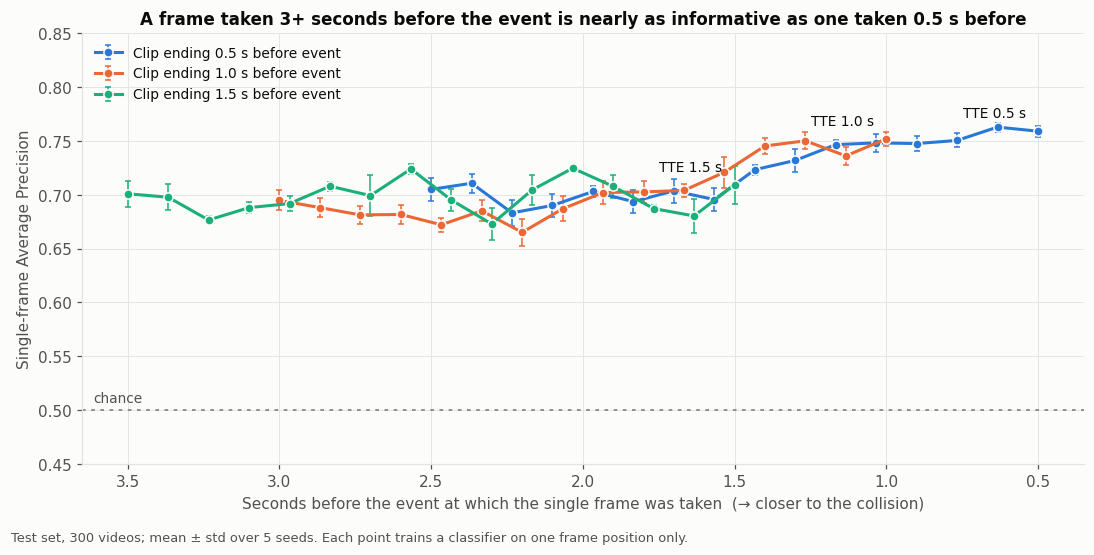

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
for tte, colour in zip(TTE_VALUES, [BLUE, ORANGE, AQUA]):
    sub = position_df[position_df["tte"] == tte]
    ax.errorbar(sub["seconds_before_event"], sub["AP_mean"], yerr=sub["AP_std"], color=colour, linewidth=2, marker="o",
                markersize=6, markeredgecolor=SURFACE, capsize=2, elinewidth=1, label=f"Clip ending {tte} s before event")
    last = sub.sort_values("seconds_before_event").iloc[0]
    ax.annotate(f"TTE {tte} s", (last["seconds_before_event"], last["AP_mean"]), xytext=(-8, 9), textcoords="offset points",
                ha="right", fontsize=9, color=INK)
ax.axhline(0.5, color=NEUTRAL, linestyle=(0, (2, 3)), linewidth=1.2)
ax.annotate("chance", (3.45, 0.5), xytext=(0, 5), textcoords="offset points", ha="right", color=INK_2, fontsize=9)
ax.invert_xaxis()
ax.set_xlabel("Seconds before the event at which the single frame was taken  (→ closer to the collision)")
ax.set_ylabel("Single-frame Average Precision")
ax.set_ylim(0.45, 0.85)
ax.legend(loc="upper left", fontsize=9)
ax.set_title("A frame taken 3+ seconds before the event is nearly as informative as one taken 0.5 s before")
fig.text(0.01, 0.005, "Test set, 300 videos; mean ± std over 5 seeds. Each point trains a classifier on one frame position only.",
         fontsize=8.5, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIGURE_DIR / "failure_fig1_frame_position.png", dpi=170)
plt.show()

## 4. Alert-timing analysis — can the model detect positives whose hazard is not yet apparent?

Each positive video has a `time_of_alert`: when the annotators judged the danger to become apparent (mean about 1.6 s before the event). A clip
that ends **before** the alert shows a scene in which the hazard has not yet been flagged; a clip that ends **after** the alert contains
the developing hazard.

If the model detected the hazard itself, it should do clearly better on *after-alert* positives. If it recognises something else
(scene type, camera, road context), the two groups should score similarly. Each group is compared against all negatives of the same
TTE (AUC; 0.5 = chance).

In [6]:
rng = np.random.default_rng(0)


def group_auc(prob, mask_pos, mask_neg, n_boot=N_BOOTSTRAP):
    pos, neg = prob[mask_pos], prob[mask_neg]
    y = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
    s = np.r_[pos, neg]
    est = roc_auc_score(y, s)
    boots = []
    for _ in range(n_boot):
        bp = rng.choice(pos, len(pos))
        bn = rng.choice(neg, len(neg))
        boots.append(roc_auc_score(np.r_[np.ones(len(bp)), np.zeros(len(bn))], np.r_[bp, bn]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return est, lo, hi


alert_rows = []
for tte in TTE_VALUES:
    meta = val_meta[tte]
    is_pos, is_neg = meta["target"].to_numpy() == 1, meta["target"].to_numpy() == 0
    before = is_pos & (meta["prediction_time"].to_numpy() < meta["time_of_alert"].to_numpy())
    after = is_pos & ~before
    for name in ["lstm", "last_frame", "optical_flow"]:
        for label, mask in [("ends before alert", before), ("ends after alert", after)]:
            if mask.sum() < 5:
                continue
            est, lo, hi = group_auc(ens[(name, tte)], mask, is_neg)
            alert_rows.append({"tte": tte, "model": name, "group": label, "n_positives": int(mask.sum()),
                               "AUC_vs_negatives": est, "ci_low": lo, "ci_high": hi})
alert_df = pd.DataFrame(alert_rows)
alert_df.to_csv(RESULTS_DIR / "failure_alert_timing.csv", index=False)
print(alert_df.round(3).to_string(index=False))

 tte        model             group  n_positives  AUC_vs_negatives  ci_low  ci_high
 0.5         lstm ends before alert            9             0.568   0.367    0.738
 0.5         lstm  ends after alert          141             0.767   0.713    0.819
 0.5   last_frame ends before alert            9             0.530   0.338    0.723
 0.5   last_frame  ends after alert          141             0.766   0.711    0.820
 0.5 optical_flow ends before alert            9             0.676   0.519    0.832
 0.5 optical_flow  ends after alert          141             0.583   0.521    0.646
 1.0         lstm ends before alert           46             0.661   0.568    0.748
 1.0         lstm  ends after alert          104             0.759   0.696    0.823
 1.0   last_frame ends before alert           46             0.666   0.574    0.752
 1.0   last_frame  ends after alert          104             0.758   0.693    0.818
 1.0 optical_flow ends before alert           46             0.658   0.569  

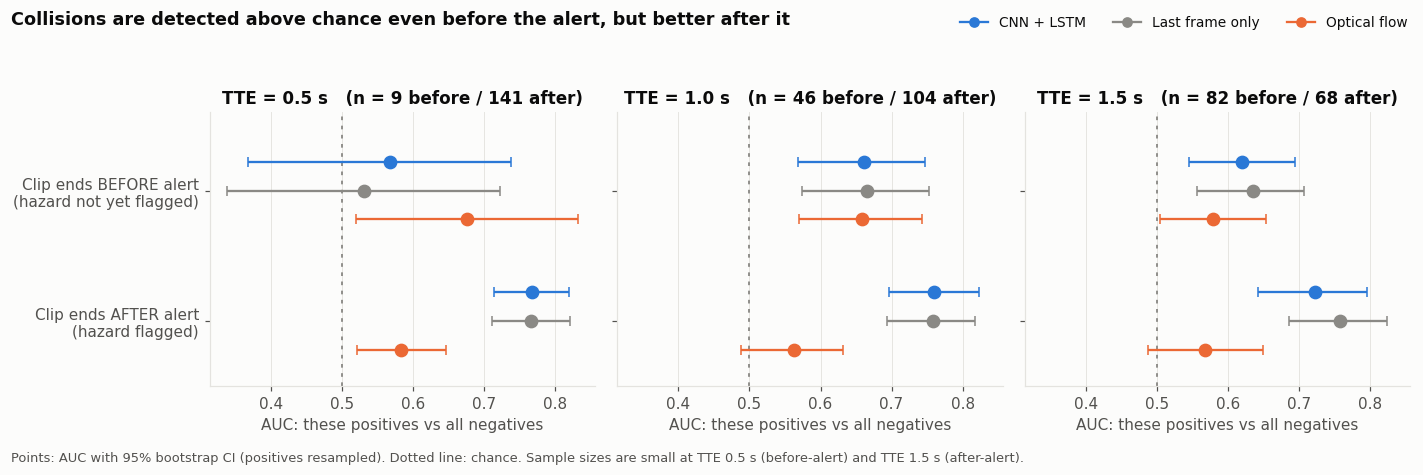

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
rows = [("lstm", "CNN + LSTM", BLUE), ("last_frame", "Last frame only", NEUTRAL), ("optical_flow", "Optical flow", ORANGE)]
y_base = {"ends before alert": 1, "ends after alert": 0}
for ax, tte in zip(axes, TTE_VALUES):
    ax.axvline(0.5, color=NEUTRAL, linestyle=(0, (2, 3)), linewidth=1.2, zorder=1)
    for k, (name, label, colour) in enumerate(rows):
        for group, y0 in y_base.items():
            sel = alert_df[(alert_df["tte"] == tte) & (alert_df["model"] == name) & (alert_df["group"] == group)]
            if sel.empty:
                continue
            r = sel.iloc[0]
            y = y0 + (1 - k) * 0.22
            ax.errorbar(r["AUC_vs_negatives"], y, xerr=[[r["AUC_vs_negatives"] - r["ci_low"]], [r["ci_high"] - r["AUC_vs_negatives"]]],
                        fmt="o", markersize=8, color=colour, capsize=3, elinewidth=1.5, zorder=3)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Clip ends AFTER alert\n(hazard flagged)", "Clip ends BEFORE alert\n(hazard not yet flagged)"])
    npos = {g: int(alert_df[(alert_df["tte"] == tte) & (alert_df["group"] == g)]["n_positives"].max()) if not alert_df[(alert_df["tte"] == tte) & (alert_df["group"] == g)].empty else 0 for g in y_base}
    ax.set_title(f"TTE = {tte} s   (n = {npos['ends before alert']} before / {npos['ends after alert']} after)")
    ax.set_xlabel("AUC: these positives vs all negatives")
    ax.set_ylim(-0.5, 1.6)
    ax.grid(axis="y", visible=False)
handles = [plt.Line2D([], [], color=c, marker="o", linewidth=1.5, label=l) for _, l, c in rows]
fig.legend(handles=handles, loc="upper right", bbox_to_anchor=(0.995, 0.995), ncol=3, fontsize=9)
fig.suptitle("Collisions are detected above chance even before the alert, but better after it",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.text(0.01, 0.005, "Points: AUC with 95% bootstrap CI (positives resampled). Dotted line: chance. Sample sizes are small at TTE 0.5 s (before-alert) and TTE 1.5 s (after-alert).",
         fontsize=8.5, color=INK_2)
fig.tight_layout(rect=(0, 0.03, 1, 0.92))
fig.savefig(FIGURE_DIR / "failure_fig2_alert_timing.png", dpi=170)
plt.show()

## 5. Shortcut checks using metadata only

If positives and negatives differed in something other than the scene, a model could exploit it without understanding collisions.
We check two metadata features with a one-feature logistic regression (fitted on train, scored on the test set; AUC 0.5 = chance):

* `prediction_time` — negatives were sampled to match the positive distribution, so this should be near chance.
* the **video id** — which could encode collection order.

**Result (see below): the video id separates the classes perfectly (AUC 1.000).** In this dataset every collision video has id ≤ 1039 and every normal video has id ≥ 1040.
Our models never see the id (they receive only ResNet activations; the id is used only to locate the video file), so no reported
number is invalid. But it is a warning: collision and normal videos were evidently assembled in separate blocks, and if the blocks differ
in camera, device, region, time of day or recording batch, a model can score well by recognising *that*, not the collision. That is
consistent with the single-frame result in section 3, and it cannot be ruled out from the features alone.

In [8]:
rows = []
for tte in TTE_VALUES:
    tr = train_clips[train_clips["tte"] == tte].reset_index(drop=True)
    tr_id = tr["id"].astype(float).astype(int).to_numpy()
    va = val_meta[tte]
    for label, tr_x, va_x in [("prediction_time", tr[["prediction_time"]].to_numpy(), va[["prediction_time"]].to_numpy()),
                              ("video id", tr_id[:, None], va[["id"]].to_numpy())]:
        clf = Pipeline([("s", StandardScaler()), ("c", LogisticRegression())]).fit(tr_x, tr["target"].to_numpy())
        p = clf.predict_proba(va_x)[:, 1]
        # Also report the raw, model-free direction: AUC of the feature itself.
        rows.append({"tte": tte, "metadata_feature": label, "test_AUC": roc_auc_score(va["target"], p),
                     "test_AP": average_precision_score(va["target"], p)})
shortcut_df = pd.DataFrame(rows)
shortcut_df.to_csv(RESULTS_DIR / "failure_metadata_shortcuts.csv", index=False)
print(shortcut_df.round(3).to_string(index=False))

# Video-id ranges per class over the whole labelled set (train + validation).
labelled = pd.concat([pd.read_csv(PROCESSED_DIR / "train_split.csv"), val_split])
labelled["id"] = labelled["id"].astype(int)
id_ranges = labelled.groupby("target")["id"].agg(["min", "max", "count"])
print("Video-id range by class (0 = normal, 1 = collision):")
print(id_ranges.to_string())
overlap = (labelled[labelled["target"] == 1]["id"].max() >= labelled[labelled["target"] == 0]["id"].min())
print("Id ranges overlap between classes:", bool(overlap))
assert not overlap, "expected the class blocks to be disjoint"

 tte metadata_feature  test_AUC  test_AP
 0.5  prediction_time     0.534    0.504
 0.5         video id     1.000    1.000
 1.0  prediction_time     0.533    0.503
 1.0         video id     1.000    1.000
 1.5  prediction_time     0.502    0.479
 1.5         video id     1.000    1.000
Video-id range by class (0 = normal, 1 = collision):
         min   max  count
target                   
0       1040  2139    750
1          0  1039    750
Id ranges overlap between classes: False


## 6. Where do errors occur? Position of the prediction within the video

Test clips are split into terciles of `prediction_time` (pooled over TTEs). AP is computed within each tercile for CNN + LSTM and the last-frame model, so we can see
whether performance depends on how far into the video the prediction point lies.

In [9]:
all_pred = predictions.copy()
all_pred["time_bin"] = pd.qcut(all_pred["prediction_time"], 3, labels=["early third", "middle third", "late third"])
rows = []
for tte in TTE_VALUES:
    sub_tte = all_pred[all_pred["tte"] == tte]
    for bin_label, sub in sub_tte.groupby("time_bin", observed=True):
        if sub["target"].nunique() < 2:
            continue
        row = {"tte": tte, "prediction_time_bin": bin_label, "n": len(sub), "positives": int(sub["target"].sum()),
               "range_s": f"{sub['prediction_time'].min():.1f}–{sub['prediction_time'].max():.1f}"}
        for name in ["lstm", "last_frame", "optical_flow"]:
            row[f"AP_{name}"] = average_precision_score(sub["target"], sub[f"p_{name}"])
            row[f"err_{name}"] = float(((sub[f"p_{name}"] >= 0.5).astype(int) != sub["target"]).mean())
        rows.append(row)
position_error_df = pd.DataFrame(rows)
position_error_df.to_csv(RESULTS_DIR / "failure_by_prediction_time.csv", index=False)
print(position_error_df.round(3).to_string(index=False))

 tte prediction_time_bin   n  positives   range_s  AP_lstm  err_lstm  AP_last_frame  err_last_frame  AP_optical_flow  err_optical_flow
 0.5         early third  62         24  3.4–18.1    0.584     0.355          0.598           0.387            0.410             0.452
 0.5        middle third  84         46 18.2–19.1    0.882     0.238          0.886           0.202            0.679             0.429
 0.5          late third 154         80 19.1–22.3    0.751     0.357          0.738           0.357            0.575             0.481
 1.0         early third  98         42  2.9–18.1    0.682     0.367          0.693           0.327            0.488             0.500
 1.0        middle third 105         58 18.1–19.1    0.791     0.343          0.793           0.362            0.670             0.419
 1.0          late third  97         50 19.1–35.4    0.784     0.361          0.770           0.340            0.552             0.495
 1.5         early third 142         71  2.4–18.1    0.

## 7. Which videos fail at every horizon?

A video is a **persistent error** if the CNN + LSTM seed-ensemble misclassifies it (probability threshold 0.5) at all three TTEs.
Such videos are the best candidates for visual inspection. The table gives the video id and the clip window, so the frames can be extracted
from `data/raw/train/{id:05d}.mp4` wherever the raw videos are available (they are not on every machine).

In [10]:
wide = predictions.pivot(index="id", columns="tte", values="p_lstm")
wide.columns = [f"p_lstm_tte_{c}" for c in wide.columns]
target = predictions.drop_duplicates("id").set_index("id")["target"]
wide["target"] = target
wrong = pd.DataFrame({f"wrong_{t}": ((wide[f"p_lstm_tte_{t}"] >= 0.5).astype(int) != wide["target"]) for t in TTE_VALUES})
wide["n_wrong"] = wrong.sum(axis=1)
wide["mean_p_lstm"] = wide[[f"p_lstm_tte_{t}" for t in TTE_VALUES]].mean(axis=1)

clip_info = predictions[predictions["tte"] == 1.0].set_index("id")[["clip_start", "clip_end", "time_of_event", "time_of_alert"]]
cases = wide.join(clip_info)
persistent = cases[cases["n_wrong"] == 3].copy()
persistent["error_type"] = np.where(persistent["target"] == 0, "false alarm", "missed collision")
persistent = persistent.sort_values(["error_type", "mean_p_lstm"], ascending=[True, False])
persistent.reset_index().to_csv(RESULTS_DIR / "failure_persistent_errors.csv", index=False)

print("Videos misclassified at 0, 1, 2, 3 horizons:")
print(cases["n_wrong"].value_counts().sort_index().to_string())
print(f"\nPersistent errors: {int((persistent['error_type'] == 'false alarm').sum())} false alarms, "
      f"{int((persistent['error_type'] == 'missed collision').sum())} missed collisions "
      f"(of {int((target == 0).sum())} normal / {int((target == 1).sum())} collision videos)")
print("\nMost confident persistent false alarms (normal videos flagged at every horizon):")
print(persistent[persistent["error_type"] == "false alarm"].head(8)[["mean_p_lstm", "clip_start", "clip_end"]].round(3).to_string())
print("\nMost confident persistent misses (collisions scored lowest at every horizon):")
print(persistent[persistent["error_type"] == "missed collision"].sort_values("mean_p_lstm").head(8)[
    ["mean_p_lstm", "clip_start", "clip_end", "time_of_event", "time_of_alert"]].round(3).to_string())

Videos misclassified at 0, 1, 2, 3 horizons:
n_wrong
0    152
1     38
2     39
3     71

Persistent errors: 36 false alarms, 35 missed collisions (of 150 normal / 150 collision videos)

Most confident persistent false alarms (normal videos flagged at every horizon):
      mean_p_lstm  clip_start  clip_end
id                                     
1344        0.855      16.665    18.665
1694        0.811      15.100    17.100
1950        0.793      15.915    17.915
1590        0.787      17.433    19.433
1171        0.767      14.400    16.400
1295        0.762      17.533    19.533
2024        0.760      15.733    17.733
1709        0.758      17.921    19.921

Most confident persistent misses (collisions scored lowest at every horizon):
     mean_p_lstm  clip_start  clip_end  time_of_event  time_of_alert
id                                                                  
667        0.068      15.033    17.033         18.033         17.067
896        0.076      16.600    18.600        

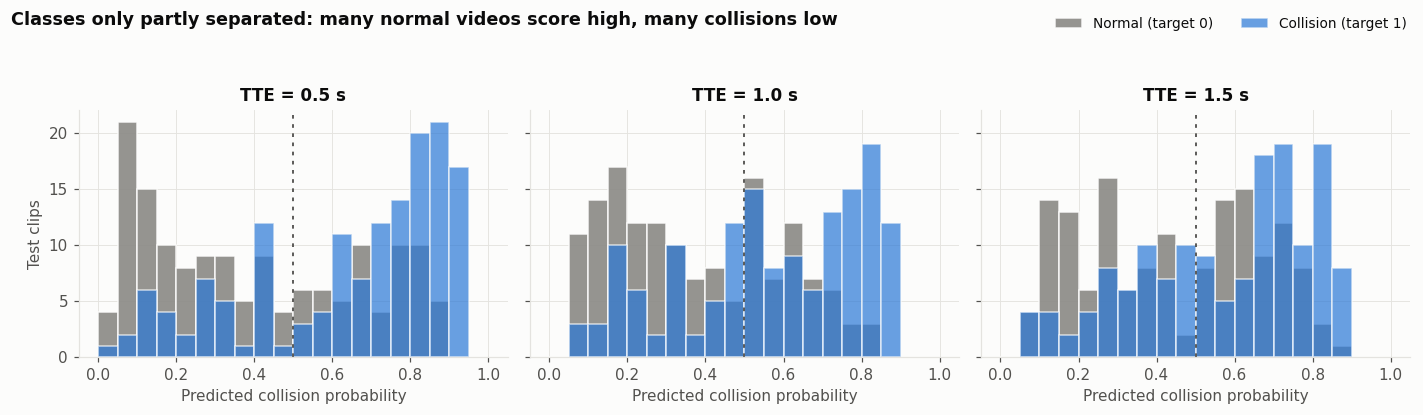

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
bins = np.linspace(0, 1, 21)
for ax, tte in zip(axes, TTE_VALUES):
    p, y = ens[("lstm", tte)], y_val[tte]
    ax.hist(p[y == 0], bins=bins, color=NEUTRAL, alpha=0.9, label="Normal (target 0)", edgecolor=SURFACE)
    ax.hist(p[y == 1], bins=bins, color=BLUE, alpha=0.7, label="Collision (target 1)", edgecolor=SURFACE)
    ax.axvline(0.5, color=INK_2, linestyle=(0, (2, 3)), linewidth=1.2)
    ax.set_title(f"TTE = {tte} s")
    ax.set_xlabel("Predicted collision probability")
axes[0].set_ylabel("Test clips")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", bbox_to_anchor=(0.995, 0.995), ncol=2, fontsize=9)
fig.suptitle("Classes only partly separated: many normal videos score high, many collisions low",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(FIGURE_DIR / "failure_fig3_score_distributions.png", dpi=170)
plt.show()

## 8. Findings (descriptive)

1. **Most of the signal is not an imminent-collision cue.** A classifier on a single frame taken more than 3 s before the event already
   reaches AP ≈ 0.70 (chance 0.5). Frames closer to the event add only a modest gain (to ≈ 0.75 within about 1.2 s of the event). The three TTE curves
   line up on the seconds-before-event axis, so the small late gain is a property of *how close to the event* the frame is, not of the clip it appears in.
2. **There is a genuine, but smaller, hazard-related component.** Positive clips that end *after* the annotated alert are detected better
   (AUC ≈ 0.72–0.77 against all negatives) than those that end *before* it (≈ 0.62–0.66), and both are above chance. The temporal CNN + LSTM and the
   single-frame model behave the same way. Optical flow shows no such pattern. Sample sizes are small at the extremes (9 before-alert positives at TTE 0.5 s).
3. **A dataset-structure confound exists.** Video ids perfectly separate the classes (collision ≤ 1039, normal ≥ 1040). The models do not use the id, but the
   blocks may differ in recording conditions; the large static-appearance signal in finding 1 is what that would predict. Verifying this needs the raw videos
   (compare resolution, frame rate, duration, brightness, camera view, and a few frames from each block).
4. **No shortcut through clip position.** `prediction_time` alone is at chance (AUC 0.50–0.53), so the negative-sampling procedure did its job. Performance is
   nonetheless lower when the prediction point falls early in the video (AP ≈ 0.58–0.68 in the early third vs ≈ 0.78–0.88 in the middle third, at TTE 0.5–1.0 s); these are small groups.
5. **Errors are persistent.** 152 of 300 test videos are classified correctly at all three horizons, and 71 (36 false alarms, 35 missed collisions) are wrong at all three.
   Their ids and clip windows are in `results/failure_persistent_errors.csv` for visual inspection once the raw videos are at hand.

## Implications for the report

* The headline result (learned features ≫ optical flow) stands, but the claim should be worded as *"CNN features separate the two video groups well,
  partly through hazard-related content and partly through static appearance"* rather than *"the model predicts collisions"*.
* Report the id-block structure as a limitation; if the raw videos allow, add a quick comparison of the two blocks' recording properties.
* A stronger test (not done): evaluate on a split that holds out id blocks or on the competition's own test videos, if available.